In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

In [2]:
ind_cell_df = pd.read_csv('h01c3/cell_positions_h01_rotated_full.csv')
ind_cell_df.rename({'Unnamed: 0': 'id_new'}, axis=1, inplace=True)

In [3]:
# Version 1:  exclude only some border neurons for correct Exc/Inh classification, focus in the good cell placement, Radius = 400 um
ind_cell_df_sub = ind_cell_df[(ind_cell_df['distance2Dcenter'] <= 250.0) & (ind_cell_df['z_new'] >= 4.0) & (ind_cell_df['z_new'] <= 170.0) & (ind_cell_df['y_new'] >= 640) & (ind_cell_df['y_new'] <= 3150)]
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='layer')
ind_cell_df_sub = ind_cell_df_sub.sort_values(by='z_new')
ind_cell_df_sub = ind_cell_df_sub.reset_index()    
print("Ntotal:%d \t NE:%d\t N_L2E:%d \t N_L2I:%d \t N_L3E:%d \t N_L3I:%d" % (len(ind_cell_df_sub), len(ind_cell_df_sub[(ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'inhibitory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'inhibitory')])))
ind_cell_df_sub

Ntotal:4396 	 NE:2973	 N_L2E:824 	 N_L2I:463 	 N_L3E:449 	 N_L3I:267


,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,955,955,8040318755,1587199,2193248,6467,1236.693906,762.913849,6.467,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,12947,12947,6075973065,1773280,1753960,7680,1038.111066,1196.693679,7.680,98.611349,6,inhibitory,L6I,interneuron,145,81,226,L6neuroninterneuron
2,9090,9090,1973925065,2690592,939168,7680,1055.922121,2423.490352,7.680,88.525801,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1933,546,2479,L3neuronexcitatory/spiny-with-atypical-tree
3,6176,6176,3532288578,2424856,1557232,7680,1332.672151,1810.279009,7.680,245.010792,4,excitatory,L4E,pyramidal neuron,798,343,1141,L4pyramidalneuron
4,7468,7468,2119671724,2512824,1087992,7680,1045.772706,2191.872058,7.680,93.992326,3,excitatory,L23E,pyramidal neuron,3038,740,3778,L3pyramidalneuron
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4391,11604,11604,63450720489,2882424,678992,167637,993.392856,2740.635678,167.637,135.221329,2,inhibitory,L23I,interneuron,77,72,149,L2neuroninterneuron
4392,10371,10371,40303011271,2509456,1464144,167637,1321.074085,1935.530838,167.637,236.206426,4,excitatory,L4E,unclassified neuron,379,117,496,L4neuronexcitatory/spiny-with-atypical-treespa...
4393,8892,8892,37523066959,2639144,797280,167637,916.497507,2481.282030,167.637,201.476772,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,279,85,364,L2neuronexcitatory/spiny-with-atypical-tree
4394,15323,15323,102228727723,2365983,1486336,169455,1240.623808,1814.680767,169.455,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...


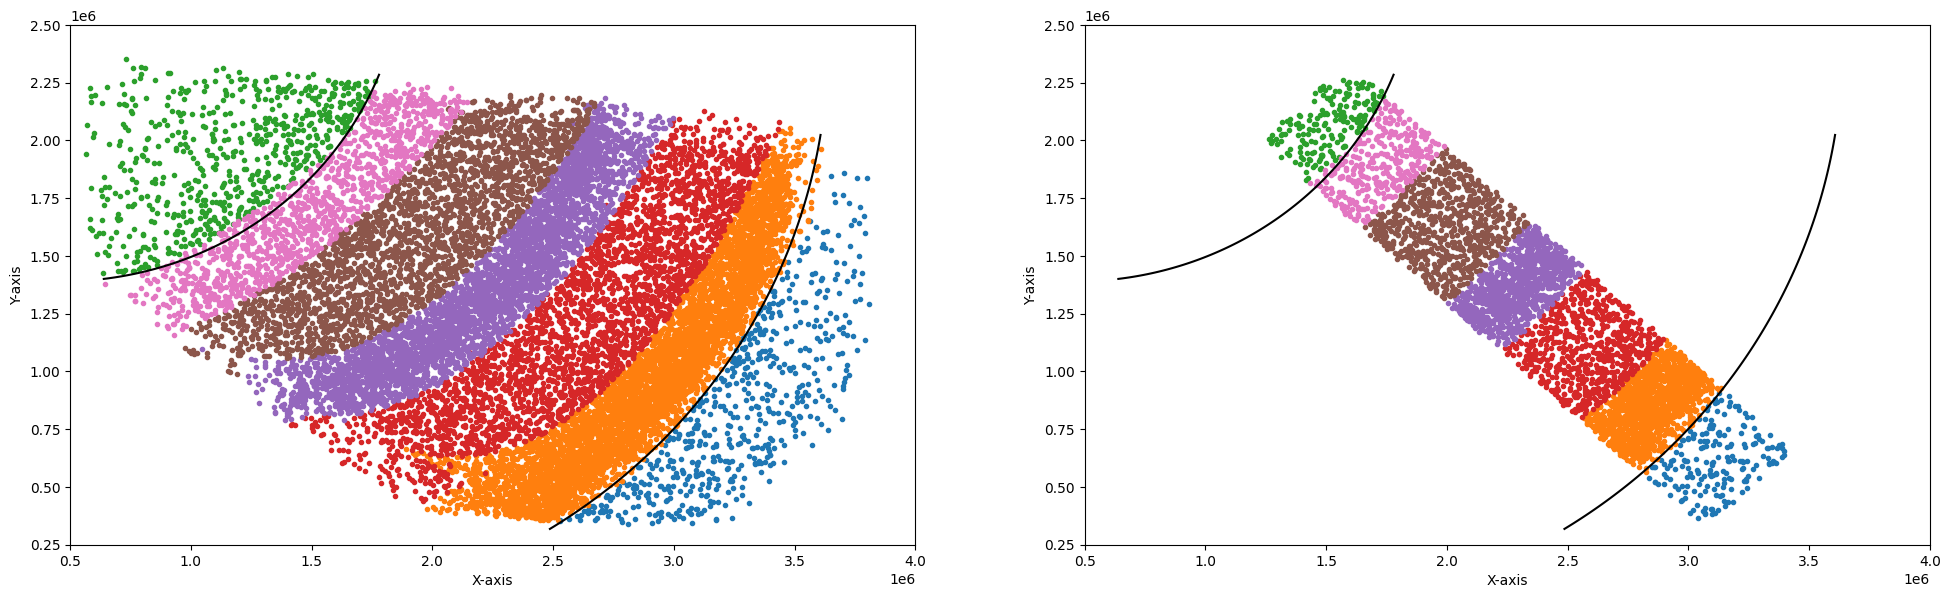

In [4]:
with open("h01c3/cortical_bounds_circles.json", "r") as f:
  bounds = json.load(f)

Fig = plt.figure(figsize=(24,6.75))

plt.subplot(121)

plt.plot(ind_cell_df[ind_cell_df['layer']==1]['x'].values,ind_cell_df[ind_cell_df['layer']==1]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==2]['x'].values,ind_cell_df[ind_cell_df['layer']==2]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==7]['x'].values,ind_cell_df[ind_cell_df['layer']==7]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==3]['x'].values,ind_cell_df[ind_cell_df['layer']==3]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==4]['x'].values,ind_cell_df[ind_cell_df['layer']==4]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==5]['x'].values,ind_cell_df[ind_cell_df['layer']==5]['y'].values, '.')
plt.plot(ind_cell_df[ind_cell_df['layer']==6]['x'].values,ind_cell_df[ind_cell_df['layer']==6]['y'].values, '.')
cdd = bounds[0]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.54*np.pi, 1.88*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')
cdd = bounds[5]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.68*np.pi, 1.95*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')

plt.xlim(500000,4000000)
plt.ylim(250000,2500000)
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

plt.subplot(122)
ind_cell_df_2 = ind_cell_df_sub

plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==1]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==1]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==2]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==2]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==7]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==7]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==3]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==3]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==4]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==4]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==5]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==5]['y'].values, '.')
plt.plot(ind_cell_df_2[ind_cell_df_2['layer']==6]['x'].values,ind_cell_df_2[ind_cell_df_2['layer']==6]['y'].values, '.')

cdd = bounds[0]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.54*np.pi, 1.88*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')
cdd = bounds[5]
center_x, center_y, radius = cdd['center'][0], cdd['center'][1] , cdd['radius']    
theta = np.linspace(1.68*np.pi, 1.95*np.pi, 100)  # Adjust point density as needed
x = 1000*(center_x + radius * np.cos(theta))
y = 1000*(center_y + radius * np.sin(theta))
plt.plot(x, y, color = 'k')

plt.xlim(500000,4000000)
plt.ylim(250000,2500000)
plt.xlabel('X-axis')
plt.ylabel('Y-axis');

plt.show() 


In [5]:
# #  Version 2: good morphologies only, focus on full morphology recontruction, axons and synapses
# ind_cell_df_sub = ind_cell_df[(ind_cell_df['distance2Dcenter'] <= 264.6) & (ind_cell_df['z_new'] >= 25.0) & (ind_cell_df['z_new'] <= 125.0) & (ind_cell_df['layer'] >= 2) & (ind_cell_df['layer'] <= 3)]
# ind_cell_df_sub = ind_cell_df_sub.sort_values(by='layer')
# ind_cell_df_sub = ind_cell_df_sub.sort_values(by='z_new')
# ind_cell_df_sub = ind_cell_df_sub.reset_index()    
# print("Ntotal:%d \t NE:%d\t N_L2E:%d \t N_L2I:%d \t N_L3E:%d \t N_L3I:%d" % (len(ind_cell_df_sub), len(ind_cell_df_sub[(ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 2) & (ind_cell_df_sub['EI'] == 'inhibitory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'excitatory')]), len(ind_cell_df_sub[(ind_cell_df_sub['layer'] == 3) & (ind_cell_df_sub['EI'] == 'inhibitory')])))
# ind_cell_df_sub

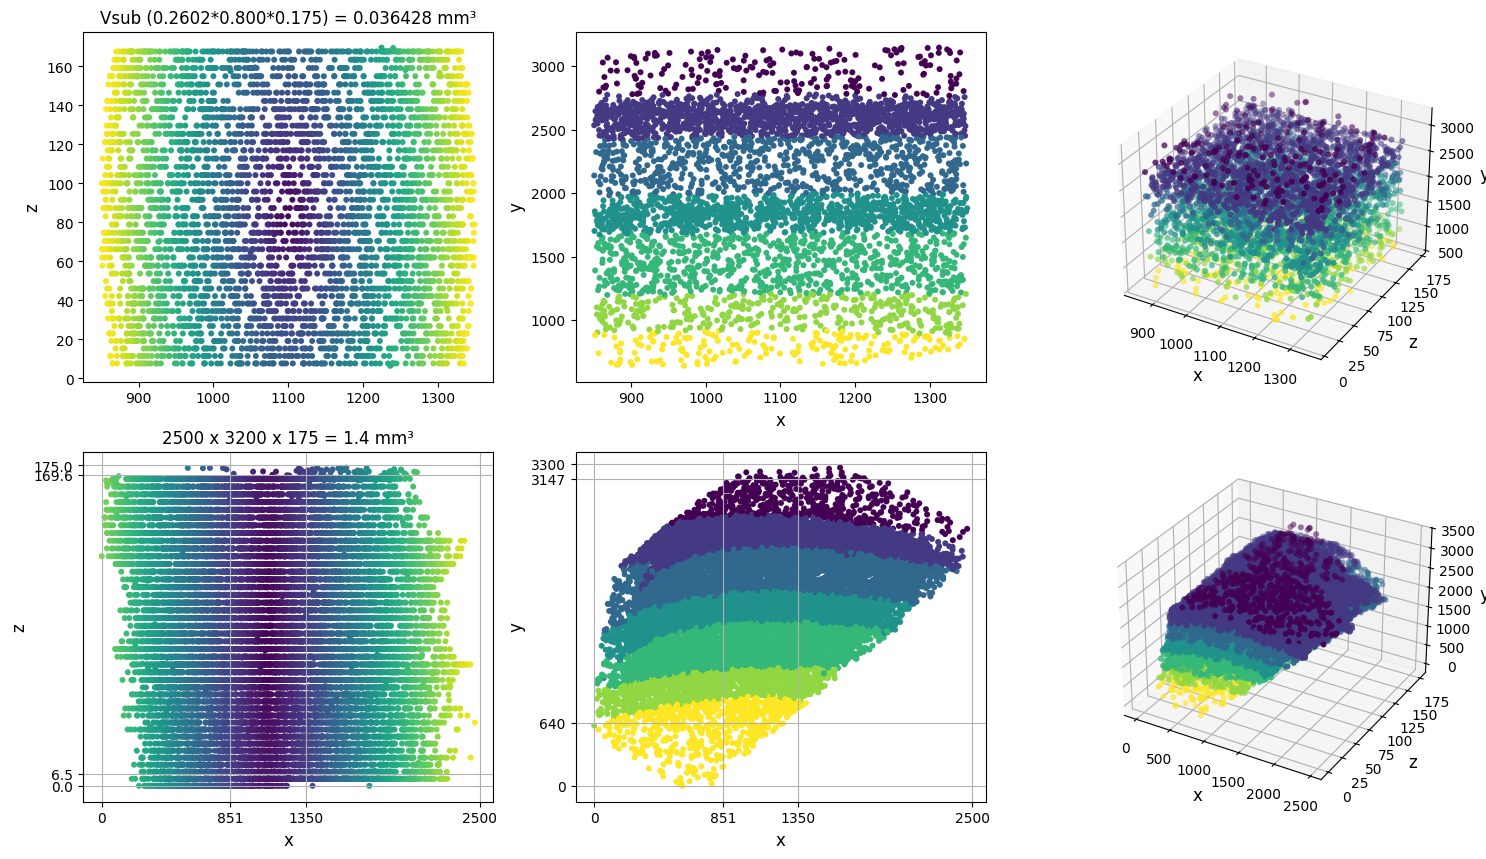

In [5]:
fig = plt.figure(figsize=(18, 10))


ax1 = fig.add_subplot(2, 3, 1)
# ax1.set_title("260.2 x 800 x 175 = 36000000 = 0.036 mm³")  # Guo 2023 π×250×250×950 = 0.186532064 mm³ 1000 L23 neurons
ax1.set_title("Vsub (0.2602*0.800*0.175) = 0.036428 mm³") 
ax1.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['z_new'], lw=0.05, s=18, c=ind_cell_df_sub['distance2Dcenter'], )
ax1.set_xlabel(' ', fontsize=12); ax1.set_ylabel('z', fontsize=12)

ax2 = fig.add_subplot(2, 3, 2)
ax2.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['y_new'], lw=0.05, s=18, c=ind_cell_df_sub['layer'], )
ax2.set_xlabel('x', fontsize=12); ax2.set_ylabel('y', fontsize=12)

ax3 = fig.add_subplot(2, 3, 3, projection='3d')
ax3.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['z_new'], ind_cell_df_sub['y_new'], lw=0.05, s=18, c=ind_cell_df_sub['layer'], );
ax3.set_xlabel('x', fontsize=12); ax3.set_ylabel('z', fontsize=12); ax3.set_zlabel('y', fontsize=12)

ax4 = fig.add_subplot(2, 3, 4)
ax4.set_title("2500 x 3200 x 175 = 1.4 mm³")
ax4.scatter(ind_cell_df['x_new'], ind_cell_df['z_new'], lw=0.05, s=18, c=ind_cell_df['distance2Dcenter'], )
ax4.set_xlabel('x', fontsize=12); ax4.set_ylabel('z', fontsize=12)
xmin = ind_cell_df_sub['x_new'].min(); xmax = ind_cell_df_sub['x_new'].max(); ymin = ind_cell_df_sub['y_new'].min(); ymax = ind_cell_df_sub['y_new'].max(); zmin = ind_cell_df_sub['z_new'].min(); zmax = ind_cell_df_sub['z_new'].max()
ax4.set_xticks([0,xmin,xmax,2500])
ax4.set_yticks([0,zmin,zmax,175])
ax4.grid(True)

ax5 = fig.add_subplot(2, 3, 5)
ax5.scatter(ind_cell_df['x_new'], ind_cell_df['y_new'], lw=0.05, s=18, c=ind_cell_df['layer'], )
ax5.set_xlabel('x', fontsize=12); ax5.set_ylabel('y', fontsize=12)
ax5.set_xticks([0,xmin,xmax,2500])
ax5.set_yticks([0,ymin,ymax,3300])
ax5.grid(True)

ax6 = fig.add_subplot(2, 3, 6, projection='3d')
ax6.scatter(ind_cell_df['x_new'], ind_cell_df['z_new'], ind_cell_df['y_new'], lw=0.05, s=18, c=ind_cell_df['layer'], );
ax6.set_xlabel('x', fontsize=12); ax6.set_ylabel('z', fontsize=12); ax6.set_zlabel('y', fontsize=12);

# Replicating the table 3 times with Z+= Zmax-Zmin=167.282

In [6]:
ind_cell_df_sub['id_new'] = [z for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub1 = ind_cell_df_sub.copy()
ind_cell_df_sub2 = ind_cell_df_sub.copy()
ind_cell_df_sub1['z_new'] = [z-167.282 for z in ind_cell_df_sub['z_new'].values]
ind_cell_df_sub2['z_new'] = [z+167.282 for z in ind_cell_df_sub['z_new'].values]

ind_cell_df_sub1['id_new'] = [z+2*ind_cell_df_sub['id_new'].size for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub2['id_new'] = [z+3*ind_cell_df_sub['id_new'].size for z in range(ind_cell_df_sub['id_new'].size)]
ind_cell_df_sub3 = pd.concat([ind_cell_df_sub1, ind_cell_df_sub, ind_cell_df_sub2], ignore_index=True)
ind_cell_df_sub3

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,955,8792,8040318755,1587199,2193248,6467,1236.693906,762.913849,-160.815,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,12947,8793,6075973065,1773280,1753960,7680,1038.111066,1196.693679,-159.602,98.611349,6,inhibitory,L6I,interneuron,145,81,226,L6neuroninterneuron
2,9090,8794,1973925065,2690592,939168,7680,1055.922121,2423.490352,-159.602,88.525801,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1933,546,2479,L3neuronexcitatory/spiny-with-atypical-tree
3,6176,8795,3532288578,2424856,1557232,7680,1332.672151,1810.279009,-159.602,245.010792,4,excitatory,L4E,pyramidal neuron,798,343,1141,L4pyramidalneuron
4,7468,8796,2119671724,2512824,1087992,7680,1045.772706,2191.872058,-159.602,93.992326,3,excitatory,L23E,pyramidal neuron,3038,740,3778,L3pyramidalneuron
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13183,11604,17579,63450720489,2882424,678992,167637,993.392856,2740.635678,334.919,135.221329,2,inhibitory,L23I,interneuron,77,72,149,L2neuroninterneuron
13184,10371,17580,40303011271,2509456,1464144,167637,1321.074085,1935.530838,334.919,236.206426,4,excitatory,L4E,unclassified neuron,379,117,496,L4neuronexcitatory/spiny-with-atypical-treespa...
13185,8892,17581,37523066959,2639144,797280,167637,916.497507,2481.282030,334.919,201.476772,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,279,85,364,L2neuronexcitatory/spiny-with-atypical-tree
13186,15323,17582,102228727723,2365983,1486336,169455,1240.623808,1814.680767,336.737,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...


Text(0.5, 0, 'z (um)')

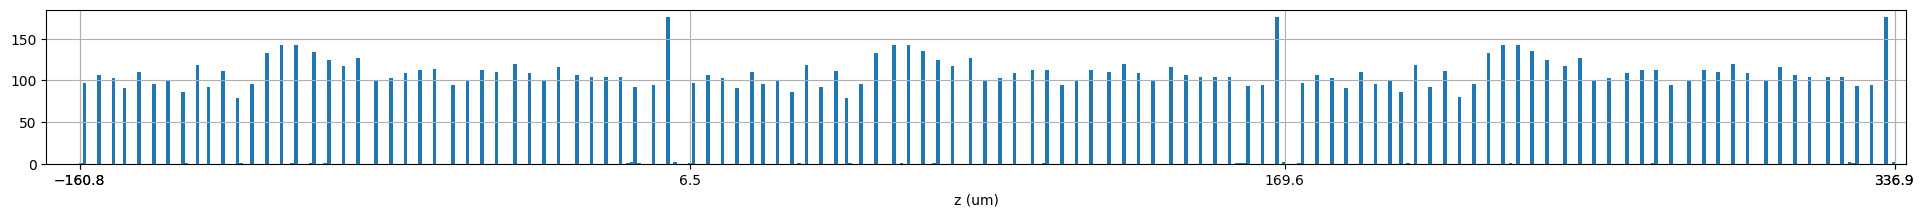

In [9]:
ind_cell_df_sub3['z_new'].hist(bins=range(-170,340,1), figsize=(24,2))
plt.xlim(-170, 340)
plt.xticks([ind_cell_df_sub3['z_new'].min(),ind_cell_df_sub1['z_new'].min(),ind_cell_df_sub['z_new'].min(),ind_cell_df_sub['z_new'].max(),ind_cell_df_sub2['z_new'].max(),ind_cell_df_sub3['z_new'].max()]);
plt.xlabel('z (um)')

In [10]:
def distance2Dmean(gidpre, mean_x, mean_z):
    return np.sqrt(np.power(ind_cell_df_sub3['x_new'][gidpre]-mean_x,2)+np.power(ind_cell_df_sub3['z_new'][gidpre]-mean_z,2))

In [11]:
mean_z = ind_cell_df_sub['z_new'].mean()
mean_x = 1100.0
mean_x, mean_z

(1100.0, 87.47887784349409)

In [12]:
ind_cell_df_sub3['distance2Dcenter_new'] = [distance2Dmean(gidpre, mean_x, mean_z) for gidpre in range(ind_cell_df_sub3['id_new'].size)]
ind_cell_df_sub3

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,distance2Dcenter_new
0,955,8792,8040318755,1587199,2193248,6467,1236.693906,762.913849,-160.815,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron,283.434426
1,12947,8793,6075973065,1773280,1753960,7680,1038.111066,1196.693679,-159.602,98.611349,6,inhibitory,L6I,interneuron,145,81,226,L6neuroninterneuron,254.713958
2,9090,8794,1973925065,2690592,939168,7680,1055.922121,2423.490352,-159.602,88.525801,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1933,546,2479,L3neuronexcitatory/spiny-with-atypical-tree,250.981712
3,6176,8795,3532288578,2424856,1557232,7680,1332.672151,1810.279009,-159.602,245.010792,4,excitatory,L4E,pyramidal neuron,798,343,1141,L4pyramidalneuron,339.389585
4,7468,8796,2119671724,2512824,1087992,7680,1045.772706,2191.872058,-159.602,93.992326,3,excitatory,L23E,pyramidal neuron,3038,740,3778,L3pyramidalneuron,252.961577
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13183,11604,17579,63450720489,2882424,678992,167637,993.392856,2740.635678,334.919,135.221329,2,inhibitory,L23I,interneuron,77,72,149,L2neuroninterneuron,269.428464
13184,10371,17580,40303011271,2509456,1464144,167637,1321.074085,1935.530838,334.919,236.206426,4,excitatory,L4E,unclassified neuron,379,117,496,L4neuronexcitatory/spiny-with-atypical-treespa...,331.813751
13185,8892,17581,37523066959,2639144,797280,167637,916.497507,2481.282030,334.919,201.476772,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,279,85,364,L2neuronexcitatory/spiny-with-atypical-tree,308.058077
13186,15323,17582,102228727723,2365983,1486336,169455,1240.623808,1814.680767,336.737,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...,286.189914


In [13]:
ind_cell_df_sub['y_new'].min(), ind_cell_df_sub['y_new'].max(), ind_cell_df_sub3['z_new'].min(), ind_cell_df_sub3['z_new'].max()

(640.388902839393, 3146.75194428238, -160.815, 336.901)

In [14]:
ind_cell_df_cylinder = ind_cell_df_sub3[(ind_cell_df_sub3['distance2Dcenter_new'] < 250) & (ind_cell_df_sub3['y_new'] >= 650.0) & (ind_cell_df_sub3['y_new'] <= 3250)]
ind_cell_df_cylinder

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,distance2Dcenter_new
8,15556,8800,4912243763,2065912,1525440,7680,1066.969232,1566.858621,-159.602,83.576250,5,inhibitory,L5I,unclassified neuron,61,58,119,L5neuronunclassified-neuron,249.278944
11,1043,8803,7006435893,1637736,1991088,7680,1121.619896,936.639570,-159.602,79.758246,6,excitatory,L6E,pyramidal neuron,443,195,638,L6pyramidalneuronbipolar,248.024959
13,5472,8805,2673749746,2660632,1072944,7680,1134.420351,2311.099748,-159.602,84.135121,3,excitatory,L23E,pyramidal neuron,5839,1745,7584,L3pyramidalneuron,249.466873
20,12937,8812,4302229447,2302176,1327584,7680,1080.413930,1874.733457,-159.602,79.231131,4,inhibitory,L4I,interneuron,643,302,945,L4neuroninterneuron,247.855955
23,13705,8815,987088265,3240208,524872,7680,1121.122622,3108.667568,-159.602,79.624890,1,inhibitory,L1I,interneuron,12,30,42,L1neuroninterneuron,247.982107
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13131,2742,17527,33326462360,1618568,1963400,167637,1088.252034,941.180862,334.919,84.010353,6,excitatory,L6E,pyramidal neuron,2056,441,2497,L6pyramidalneuron,247.718850
13134,9573,17530,41814257914,1831568,1784136,167637,1099.716041,1219.341172,334.919,83.185367,5,excitatory,L5E,excitatory/spiny neuron with atypical tree,367,189,556,L5neuronexcitatory/spiny-with-atypical-tree,247.440285
13144,9084,17540,37873608823,2889096,803424,167637,1089.717903,2661.583016,334.919,83.817935,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,418,115,533,L2neuronexcitatory/spiny-with-atypical-tree,247.653661
13162,6892,17558,2397543162,2890192,855904,167637,1129.184205,2626.974309,334.919,88.155786,2,excitatory,L23E,pyramidal neuron,2245,694,2939,L2pyramidalneuron,249.155237


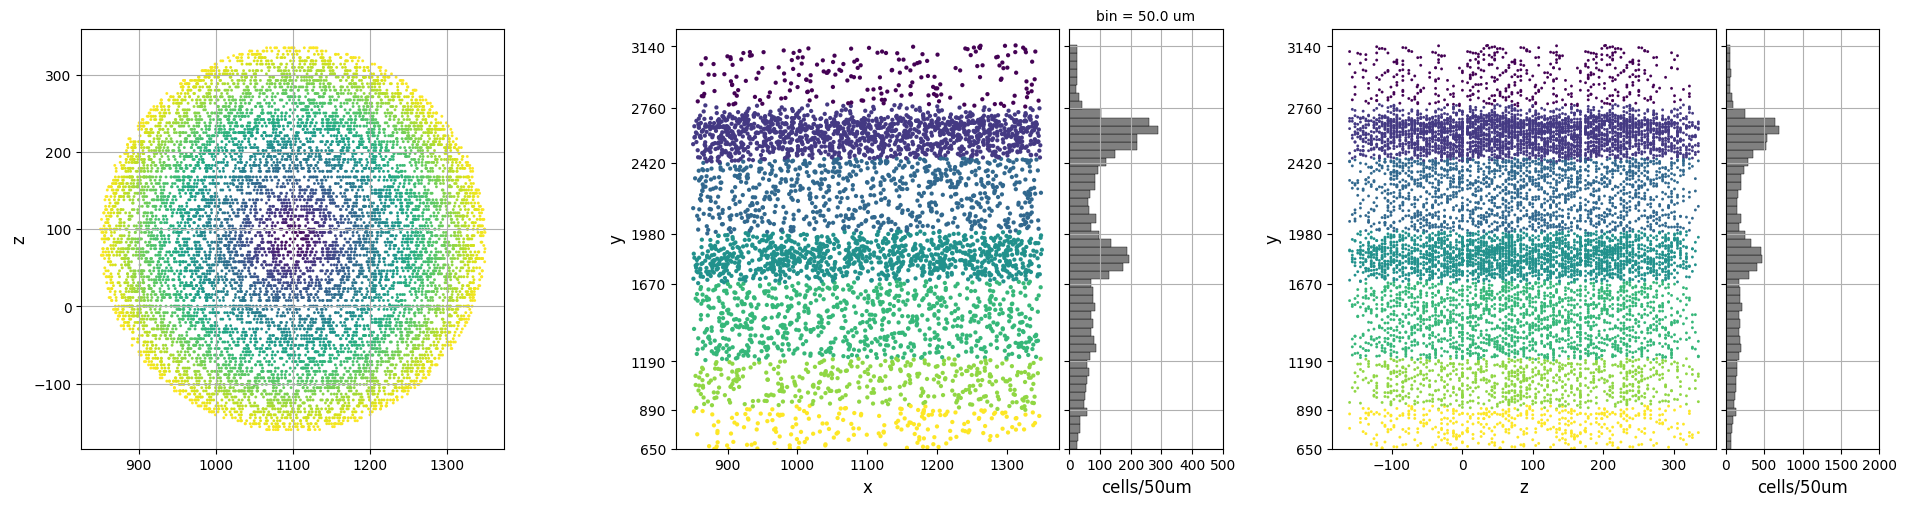

In [15]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig = plt.figure(figsize=(24, 12))
lmin = [ind_cell_df_cylinder[ind_cell_df_cylinder['layer'] == 1]['y_new'].max()]
for layer in range(1,8):
    lmin.append(ind_cell_df_cylinder[ind_cell_df_cylinder['layer'] == layer]['y_new'].min())

lmin = [10*int(l/10) for l in lmin]

ax1 = fig.add_subplot(2, 3, 1)
ax1.scatter(ind_cell_df_cylinder['x_new'], ind_cell_df_cylinder['z_new'], lw=0.05, s=4, c=ind_cell_df_cylinder['distance2Dcenter_new'], )
ax1.set_xlabel(' ', fontsize=12); ax1.set_ylabel('z', fontsize=12)
ax1.grid(True)
ax1.set_aspect('equal')

ax2 = fig.add_subplot(2, 3, 2)
ax2.scatter(ind_cell_df_sub['x_new'], ind_cell_df_sub['y_new'], lw=0.05, s=9, c=ind_cell_df_sub['layer'], )
ax2.set_xlabel('x', fontsize=12); ax2.set_ylabel('y', fontsize=12)

ax2h = make_axes_locatable(ax2).append_axes('right', size='40%', pad=0.1, sharey=ax2)
ybins = np.linspace(650, 3250, 53)  # ~50 um bins
dy = ybins[1] - ybins[0]
ax2h.hist(ind_cell_df_sub['y_new'], bins=ybins, orientation='horizontal', color='gray', edgecolor='k', lw=0.3)  # 1e9: um³ -> mm³
ax2h.set_xlabel('cells/50um', fontsize=12); ax2h.set_title('bin = %.1f um' % dy, fontsize=10)
ax2h.tick_params(labelleft=False)
ax2h.set_ylim([650,3250])
ax2h.set_yticks(lmin)
ax2h.set_xticks([0,100,200,300,400,500])
ax2h.grid(True)

ax3 = fig.add_subplot(2, 3, 3)
ax3.scatter(ind_cell_df_cylinder['z_new'], ind_cell_df_cylinder['y_new'], lw=0.05, s=4, c=ind_cell_df_cylinder['layer']);
ax3.set_xlabel('z', fontsize=12); ax3.set_ylabel('y', fontsize=12)
ax3h = make_axes_locatable(ax3).append_axes('right', size='40%', pad=0.1, sharey=ax3)
ybins = np.linspace(650, 3250, 53)  # ~50 um bins
dy = ybins[1] - ybins[0]
ax3h.hist(ind_cell_df_cylinder['y_new'], bins=ybins, orientation='horizontal', color='gray', edgecolor='k', lw=0.3)  # 1e9: um³ -> mm³
ax3h.set_xlabel('cells/50um', fontsize=12); ax2h.set_title('bin = %.1f um' % dy, fontsize=10)
ax3h.tick_params(labelleft=False)
ax3h.set_ylim([650,3250])
ax3h.set_yticks(lmin)
ax3h.set_xticks([0,500,1000,1500,2000])
ax3h.grid(True)

In [16]:
ind_cell_df_cylinder['x_n'] = ind_cell_df_cylinder['x_new'] - ind_cell_df_cylinder['x_new'].min()
ind_cell_df_cylinder['y_n'] = ind_cell_df_cylinder['y_new'] - ind_cell_df_cylinder['y_new'].min()
ind_cell_df_cylinder['z_n'] = ind_cell_df_cylinder['z_new'] - ind_cell_df_cylinder['z_new'].min()
ind_cell_df_cylinder

/tmp/ipykernel_2648088/3969669749.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ind_cell_df_cylinder['x_n'] = ind_cell_df_cylinder['x_new'] - ind_cell_df_cylinder['x_new'].min()
/tmp/ipykernel_2648088/3969669749.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ind_cell_df_cylinder['y_n'] = ind_cell_df_cylinder['y_new'] - ind_cell_df_cylinder['y_new'].min()
/tmp/ipykernel_2648088/3969669749.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,...,mtype,type,Esyns,Isyns,syns,info,distance2Dcenter_new,x_n,y_n,z_n
8,15556,8800,4912243763,2065912,1525440,7680,1066.969232,1566.858621,-159.602,83.576250,...,L5I,unclassified neuron,61,58,119,L5neuronunclassified-neuron,249.278944,216.352238,915.721118,0.000
11,1043,8803,7006435893,1637736,1991088,7680,1121.619896,936.639570,-159.602,79.758246,...,L6E,pyramidal neuron,443,195,638,L6pyramidalneuronbipolar,248.024959,271.002902,285.502067,0.000
13,5472,8805,2673749746,2660632,1072944,7680,1134.420351,2311.099748,-159.602,84.135121,...,L23E,pyramidal neuron,5839,1745,7584,L3pyramidalneuron,249.466873,283.803356,1659.962245,0.000
20,12937,8812,4302229447,2302176,1327584,7680,1080.413930,1874.733457,-159.602,79.231131,...,L4I,interneuron,643,302,945,L4neuroninterneuron,247.855955,229.796935,1223.595954,0.000
23,13705,8815,987088265,3240208,524872,7680,1121.122622,3108.667568,-159.602,79.624890,...,L1I,interneuron,12,30,42,L1neuroninterneuron,247.982107,270.505627,2457.530065,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13131,2742,17527,33326462360,1618568,1963400,167637,1088.252034,941.180862,334.919,84.010353,...,L6E,pyramidal neuron,2056,441,2497,L6pyramidalneuron,247.718850,237.635039,290.043359,494.521
13134,9573,17530,41814257914,1831568,1784136,167637,1099.716041,1219.341172,334.919,83.185367,...,L5E,excitatory/spiny neuron with atypical tree,367,189,556,L5neuronexcitatory/spiny-with-atypical-tree,247.440285,249.099047,568.203669,494.521
13144,9084,17540,37873608823,2889096,803424,167637,1089.717903,2661.583016,334.919,83.817935,...,L23E,excitatory/spiny neuron with atypical tree,418,115,533,L2neuronexcitatory/spiny-with-atypical-tree,247.653661,239.100909,2010.445513,494.521
13162,6892,17558,2397543162,2890192,855904,167637,1129.184205,2626.974309,334.919,88.155786,...,L23E,pyramidal neuron,2245,694,2939,L2pyramidalneuron,249.155237,278.567211,1975.836806,494.521


In [17]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

df_plot = ind_cell_df_cylinder

fig = go.Figure()

cores_por_layer = {
    1: "#EEFF00",  
    2: "#ee0d0d",
    3: "#6b13e7",
    4: "#0B8622",  
    5: "#e01acf",  
    6: "#1e1c1e",  
    7: "#002fff",  
}

for layer in range(1,8):
    df_layer = df_plot[df_plot['layer'] == layer]
    
    if len(df_layer) == 0:
        continue
        
    cor_fixa = cores_por_layer[layer]
    nome_anat = "L"+str(layer)

    fig.add_trace(go.Scatter3d(
        x=df_layer['z_n'], 
        y=df_layer['x_n'], 
        z=df_layer['y_n'],
        mode='markers',
        marker=dict(size=2.5, color=cor_fixa, opacity=0.75),
        name=nome_anat # Nome que aparecerá na legenda
    ))

camera_diagonal_com_zoom = dict(
    up=dict(x=0, y=0, z=1),       
    center=dict(x=0, y=0, z=0),   
    eye=dict(x=1.12, y=-1.26, z=0.42)  
)

eixo_limpo = dict(
    showbackground=False, 
    showgrid=False,       
    zeroline=False,       
    showline=False        
)

fig.update_layout(
    title='', 
    scene=dict(
        xaxis_title='Z (µm)',
        yaxis_title='X (µm)',
        zaxis_title='Y (µm)',
        aspectmode='data',
        xaxis=eixo_limpo,
        yaxis=eixo_limpo, 
        zaxis=eixo_limpo
    ),
    scene_camera=camera_diagonal_com_zoom, 
    width=600,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0), 
    showlegend=True,
    legend=dict(
        itemsizing='constant', # Garante que as bolinhas de cor na legenda fiquem bem visíveis
        title="Cortex",
        x=0.95, y=0.95 # Posição da legenda
    ),
    paper_bgcolor='white',
    plot_bgcolor='white'
)

# =====================================================================
# fig.write_image("cortex_visao_diagonal_zoom.png", width=1920, height=1080, scale=2)
# print(" Imagem limpa salva com sucesso: 'cortex_visao_diagonal_zoom.png'")

fig.show()

In [17]:
# ind_cell_df_cylinder.to_csv('cylinder_Gustavo.csv', columns=['x_new', 'y_new', 'z_new', 'layer'], header=False, index=False)

# Connection matrix

In [18]:
ind_cell_df = ind_cell_df_sub
N_population = ind_cell_df['mtype'].value_counts()
ind_cell_df

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info
0,955,0,8040318755,1587199,2193248,6467,1236.693906,762.913849,6.467,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron
1,12947,1,6075973065,1773280,1753960,7680,1038.111066,1196.693679,7.680,98.611349,6,inhibitory,L6I,interneuron,145,81,226,L6neuroninterneuron
2,9090,2,1973925065,2690592,939168,7680,1055.922121,2423.490352,7.680,88.525801,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1933,546,2479,L3neuronexcitatory/spiny-with-atypical-tree
3,6176,3,3532288578,2424856,1557232,7680,1332.672151,1810.279009,7.680,245.010792,4,excitatory,L4E,pyramidal neuron,798,343,1141,L4pyramidalneuron
4,7468,4,2119671724,2512824,1087992,7680,1045.772706,2191.872058,7.680,93.992326,3,excitatory,L23E,pyramidal neuron,3038,740,3778,L3pyramidalneuron
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4391,11604,4391,63450720489,2882424,678992,167637,993.392856,2740.635678,167.637,135.221329,2,inhibitory,L23I,interneuron,77,72,149,L2neuroninterneuron
4392,10371,4392,40303011271,2509456,1464144,167637,1321.074085,1935.530838,167.637,236.206426,4,excitatory,L4E,unclassified neuron,379,117,496,L4neuronexcitatory/spiny-with-atypical-treespa...
4393,8892,4393,37523066959,2639144,797280,167637,916.497507,2481.282030,167.637,201.476772,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,279,85,364,L2neuronexcitatory/spiny-with-atypical-tree
4394,15323,4394,102228727723,2365983,1486336,169455,1240.623808,1814.680767,169.455,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...


In [19]:
N_population

L23E    1273
L4E      732
L23I     730
L5E      540
L6E      288
L4I      209
L1I      197
L5I      192
L7E      140
L6I       49
L7I       46
Name: mtype, dtype: int64

In [20]:
edges_pre_post = np.loadtxt('h01c3/edges_pre_post.txt')

In [21]:
c1, c2 = np.unique([str(a)[:-2]+', '+str(b)[:-2] for a,b in edges_pre_post],return_counts=True)
c1[c2>15], c2[c2>15]

(array(['1524667312, 2557789796', '30973073563, 31103708188',
        '36095615295, 36678107375', '37101492779, 37770758892',
        '38209095765, 39038491013', '4159329415, 3997929684',
        '4590715045, 4896065848', '4698865343, 4406144858',
        '5071249782, 5287898185', '5071249782, 5318268259',
        '5071249782, 6117557133', '5071249782, 6219969344',
        '5175470732, 6063256489', '7197958715, 7037711560',
        '7372659407, 33008496925'], dtype='<U24'),
 array([23, 20, 16, 21, 18, 17, 16, 24, 20, 30, 20, 18, 21, 20, 19]))

In [22]:
List_cell_df = set(ind_cell_df["id"].values)

index_pre_post_ = []
index_pre_post_unique = []

for a, b in edges_pre_post:

    if a in List_cell_df and b in List_cell_df and str(a)+'->'+str(b) not in index_pre_post_unique:

        index_pre_post_unique.append(str(a)+'->'+str(b))

        pre_index = ind_cell_df.index[ind_cell_df["id"] == a][0]
        post_index = ind_cell_df.index[ind_cell_df["id"] == b][0]

        mtype_pre = ind_cell_df.loc[pre_index, "mtype"]
        mtype_post = ind_cell_df.loc[post_index, "mtype"]

        x_pre = ind_cell_df.loc[pre_index, "x_new"]
        y_pre = ind_cell_df.loc[pre_index, "y_new"]
        z_pre = ind_cell_df.loc[pre_index, "z_new"]

        x_post = ind_cell_df.loc[post_index, "x_new"]
        y_post = ind_cell_df.loc[post_index, "y_new"]
        z_post = ind_cell_df.loc[post_index, "z_new"]

        distance = np.sqrt(
            (x_pre - x_post)**2 +
            (y_pre - y_post)**2 +
            (z_pre - z_post)**2
        )

        population_conn = mtype_pre + "->" + mtype_post
        
        type_pre = ind_cell_df.loc[pre_index, "EI"]
        type_post = ind_cell_df.loc[post_index, "EI"]
        general_conn = ind_cell_df.loc[pre_index, 'EI'] + "->" + ind_cell_df.loc[post_index, 'EI']

        index_pre_post_.append([pre_index,post_index,mtype_pre,mtype_post,population_conn,distance, general_conn, type_pre, type_post, int(a), int(b)])

index_pre_post_unique = pd.DataFrame(index_pre_post_, columns=["pre", "post", "mtype pre", "mtype post", "population conn", "distance", 'General conn', 'type pre', 'type post', "id_pre", "id_post"])

In [23]:
index_pre_post_unique

,pre,post,mtype pre,mtype post,population conn,distance,General conn,type pre,type post,id_pre,id_post
0,2230,1817,L23I,L4I,L23I->L4I,300.868168,inhibitory->inhibitory,inhibitory,inhibitory,31044911156,5059509351
1,3223,3498,L23E,L23I,L23E->L23I,135.941655,excitatory->inhibitory,excitatory,inhibitory,28862498148,38266229992
2,2661,1579,L23E,L23I,L23E->L23I,53.239812,excitatory->inhibitory,excitatory,inhibitory,1975281707,2484302084
3,4387,2249,L23E,L23E,L23E->L23E,173.153435,excitatory->excitatory,excitatory,excitatory,29954609809,2980517446
4,2670,3606,L23E,L23I,L23E->L23I,63.263962,excitatory->inhibitory,excitatory,inhibitory,2702573322,29938695074
...,...,...,...,...,...,...,...,...,...,...,...
9778,3547,1139,L23E,L23E,L23E->L23E,182.026567,excitatory->excitatory,excitatory,excitatory,2280851941,2440952622
9779,928,1154,L23E,L23I,L23E->L23I,101.346055,excitatory->inhibitory,excitatory,inhibitory,2339824866,3038264050
9780,2054,1140,L23E,L23E,L23E->L23E,170.866071,excitatory->excitatory,excitatory,excitatory,4012121203,3007645402
9781,723,560,L23I,L23E,L23I->L23E,83.785389,inhibitory->excitatory,inhibitory,excitatory,2499384877,2251780890


In [24]:
Kout = []

aa, bb = np.unique([index_pre_post_unique["id_pre"].values], return_counts=True)

for i,id in enumerate(ind_cell_df["id"].values):
    for ii,id2 in enumerate(aa):
        if id == id2:
            Kout.append(bb[ii])
    if len(Kout) == i:
        Kout.append(0)

    # print(i,Kout[i])

In [25]:
ind_cell_df["Kout"] = Kout
ind_cell_df

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,Kout
0,955,0,8040318755,1587199,2193248,6467,1236.693906,762.913849,6.467,157.375037,7,excitatory,L7E,pyramidal neuron,0,0,0,layer-unclassifiedpyramidalneuron,0
1,12947,1,6075973065,1773280,1753960,7680,1038.111066,1196.693679,7.680,98.611349,6,inhibitory,L6I,interneuron,145,81,226,L6neuroninterneuron,0
2,9090,2,1973925065,2690592,939168,7680,1055.922121,2423.490352,7.680,88.525801,3,excitatory,L23E,excitatory/spiny neuron with atypical tree,1933,546,2479,L3neuronexcitatory/spiny-with-atypical-tree,0
3,6176,3,3532288578,2424856,1557232,7680,1332.672151,1810.279009,7.680,245.010792,4,excitatory,L4E,pyramidal neuron,798,343,1141,L4pyramidalneuron,0
4,7468,4,2119671724,2512824,1087992,7680,1045.772706,2191.872058,7.680,93.992326,3,excitatory,L23E,pyramidal neuron,3038,740,3778,L3pyramidalneuron,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4391,11604,4391,63450720489,2882424,678992,167637,993.392856,2740.635678,167.637,135.221329,2,inhibitory,L23I,interneuron,77,72,149,L2neuroninterneuron,0
4392,10371,4392,40303011271,2509456,1464144,167637,1321.074085,1935.530838,167.637,236.206426,4,excitatory,L4E,unclassified neuron,379,117,496,L4neuronexcitatory/spiny-with-atypical-treespa...,0
4393,8892,4393,37523066959,2639144,797280,167637,916.497507,2481.282030,167.637,201.476772,2,excitatory,L23E,excitatory/spiny neuron with atypical tree,279,85,364,L2neuronexcitatory/spiny-with-atypical-tree,0
4394,15323,4394,102228727723,2365983,1486336,169455,1240.623808,1814.680767,169.455,164.318427,4,inhibitory,L4I,unclassified neuron,0,0,0,layer-unclassifiedneuronunclassified-neuronthi...,0


In [26]:
ind_cell_df[(ind_cell_df['Kout'] >= 1) & (ind_cell_df['syns'] >= 500) & (ind_cell_df['layer'] >= 2) & (ind_cell_df['layer'] <= 6)]['mtype'].value_counts()

L23E    827
L4E     310
L23I    196
L5E     168
L6E     102
L4I      48
L5I      34
L6I      11
Name: mtype, dtype: int64

In [27]:
ind_cell_df = ind_cell_df[(ind_cell_df['Kout'] >= 1) & (ind_cell_df['syns'] >= 500)]
ind_cell_df

,index,id_new,id,x,y,z,x_new,y_new,z_new,distance2Dcenter,layer,EI,mtype,type,Esyns,Isyns,syns,info,Kout
5,7570,5,4100311461,2552280,1413408,7680,1312.535279,2001.372507,7.680,225.976111,3,excitatory,L23E,pyramidal neuron,6108,1691,7799,L3pyramidalneuron,2
15,5693,15,3706478511,2314744,1402784,7680,1144.388207,1833.257121,7.680,88.680725,4,excitatory,L4E,pyramidal neuron,888,262,1150,L4pyramidalneuron,1
16,5364,16,2733191045,2990120,1006344,7680,1307.637586,2599.186005,7.680,221.375981,2,excitatory,L23E,pyramidal neuron,823,361,1184,L2pyramidalneuron,1
18,6273,18,1465327748,2771976,772328,7680,987.729740,2596.142430,7.680,136.009445,2,excitatory,L23E,pyramidal neuron,2307,913,3220,L2pyramidalneuron,1
22,6295,22,1522447195,2619240,795312,7680,901.612531,2467.922400,7.680,212.724107,2,excitatory,L23E,pyramidal neuron,4001,1415,5416,L2pyramidalneuron,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4332,9436,4332,15915938175,1715440,1808672,167637,1039.449953,1117.087926,167.637,102.888449,6,excitatory,L6E,excitatory/spiny neuron with atypical tree,492,213,705,L6neuronexcitatory/spiny-with-atypical-tree,4
4355,10626,4355,40404502148,2349816,1507648,167637,1245.439885,1788.367679,167.637,167.548456,4,inhibitory,L4I,interneuron,379,227,606,L4neuroninterneuronlot-of-axon,1
4365,9561,4365,4083900716,2273072,1188288,167637,957.981457,1947.264196,167.637,164.587336,4,excitatory,L4E,excitatory/spiny neuron with atypical tree,1332,300,1632,L4neuronexcitatory/spiny-with-atypical-tree,4
4370,6892,4370,2397543162,2890192,855904,167637,1129.184205,2626.974309,167.637,88.155786,2,excitatory,L23E,pyramidal neuron,2245,694,2939,L2pyramidalneuron,2


In [28]:
index_pre_post_unique[(index_pre_post_unique.isin(ind_cell_df['id'].values)['id_pre']) & (index_pre_post_unique.isin(ind_cell_df['id'].values)['id_post'])]

,pre,post,mtype pre,mtype post,population conn,distance,General conn,type pre,type post,id_pre,id_post
2,2661,1579,L23E,L23I,L23E->L23I,53.239812,excitatory->inhibitory,excitatory,inhibitory,1975281707,2484302084
3,4387,2249,L23E,L23E,L23E->L23E,173.153435,excitatory->excitatory,excitatory,excitatory,29954609809,2980517446
7,997,105,L23E,L23E,L23E->L23E,83.121049,excitatory->excitatory,excitatory,excitatory,2062407077,2106661563
8,2550,2599,L4E,L4E,L4E->L4E,130.605199,excitatory->excitatory,excitatory,excitatory,22003532167,3923609959
9,3805,3482,L4I,L5E,L4I->L5E,304.881617,inhibitory->excitatory,inhibitory,excitatory,49270111115,31698495230
...,...,...,...,...,...,...,...,...,...,...,...
9773,3678,888,L23I,L23E,L23I->L23E,113.404711,inhibitory->excitatory,inhibitory,excitatory,55866580890,2878631738
9775,2670,2661,L23E,L23E,L23E->L23E,39.530716,excitatory->excitatory,excitatory,excitatory,2702573322,1975281707
9776,3809,1139,L23E,L23E,L23E->L23E,110.493992,excitatory->excitatory,excitatory,excitatory,30187073170,2440952622
9778,3547,1139,L23E,L23E,L23E->L23E,182.026567,excitatory->excitatory,excitatory,excitatory,2280851941,2440952622


In [29]:
index_pre_post = index_pre_post_unique[(index_pre_post_unique.isin(ind_cell_df['id'].values)['id_pre']) & (index_pre_post_unique.isin(ind_cell_df['id'].values)['id_post'])]
aux = index_pre_post['population conn'].value_counts()
conn_prob = {'pre':[], 'post':[], 'prob':[], 'TOTAL':[]}
for connection in aux.keys():
    pre, post = connection.split('->')
    conn_prob['pre'].append(pre)
    conn_prob['post'].append(post)
    conn_prob['prob'].append(aux[connection] / ((N_population[pre]-1) * N_population[post]))
    conn_prob['TOTAL'].append(aux[connection])

conn_prob = pd.DataFrame(conn_prob)
conn_prob[conn_prob['TOTAL'] > 10]

,pre,post,prob,TOTAL
0,L23E,L23E,0.001465,2373
1,L23E,L23I,0.001243,1154
2,L23I,L23E,0.000576,535
3,L4E,L4E,0.000460,246
4,L4E,L23E,0.000157,146
5,L4E,L4I,0.000851,130
6,L23E,L4E,0.000113,105
7,L23I,L23I,0.000190,101
8,L4I,L4E,0.000624,95
9,L5I,L5E,0.000669,69


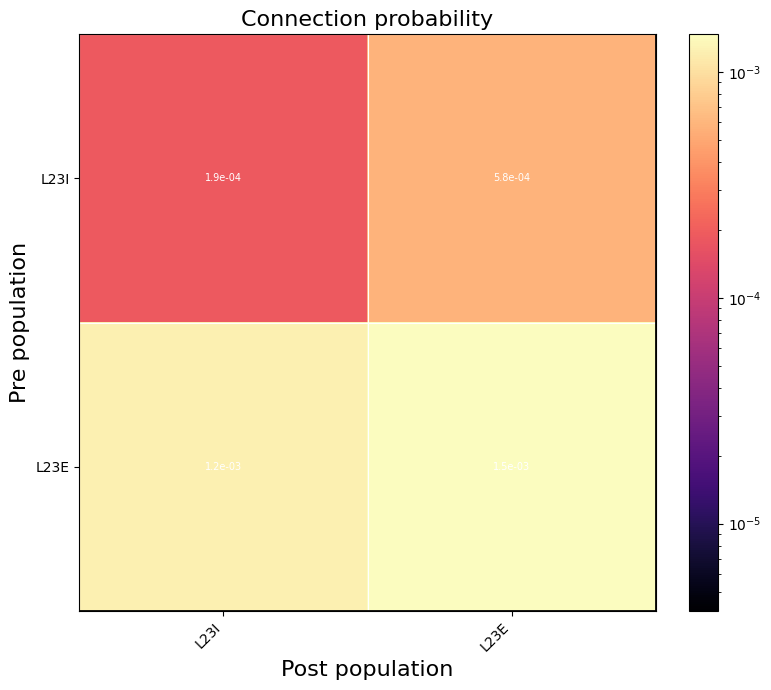

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# -----------------------------
# Population order
# -----------------------------
pop_order = [
    "L23I", "L23E",
]

# -----------------------------
# Build matrix
# -----------------------------
conn_matrix = (
    conn_prob
    .pivot(index="pre", columns="post", values="prob")
    .reindex(index=pop_order, columns=pop_order)
    .fillna(0.0)
)

data = conn_matrix.values
masked_data = np.ma.masked_where(data == 0, data)

vmin = conn_prob.loc[conn_prob["prob"] > 0, "prob"].min()
vmax = conn_prob["prob"].max()

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.cm.magma.copy()
cmap.set_bad(color="lightgray")

im = ax.imshow(
    masked_data,
    cmap=cmap,
    norm=LogNorm(vmin=vmin, vmax=vmax),
    aspect="equal"
)

# -----------------------------
# Axis ticks
# -----------------------------
ax.set_xticks(np.arange(len(pop_order)))
ax.set_yticks(np.arange(len(pop_order)))

ax.set_xticklabels(pop_order, rotation=45, ha="right")
ax.set_yticklabels(pop_order)

ax.set_xlabel("Post population", fontsize = 16)
ax.set_ylabel("Pre population", fontsize = 16)
ax.set_title("Connection probability", fontsize = 16)

ax.set_xticks(np.arange(-0.5, len(pop_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(pop_order), 1), minor=True)

ax.grid(which="minor", color="white", linestyle="-", linewidth=0.8)

ax.tick_params(which="minor", bottom=False, left=False)

layer_boundaries = [1.5]

for boundary in layer_boundaries:
    ax.axhline(boundary, color="black", linewidth=2.0)
    ax.axvline(boundary, color="black", linewidth=2.0)

# -----------------------------
# Add values inside cells
# -----------------------------
for i in range(len(pop_order)):
    for j in range(len(pop_order)):
        value = conn_matrix.iloc[i, j]

        if value == 0:
            ax.text(j, i, "0", ha="center", va="center",
                    color="black", fontsize=8)
        else:
            ax.text(j, i, f"{value:.1e}", ha="center", va="center",
                    color="white", fontsize=7)

# -----------------------------
# Colorbar
# -----------------------------
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
#plt.savefig('Connection_Probability_full.png', format='png', dpi=100)
plt.show()

Text(0.5, 0, 'Distance (um)')

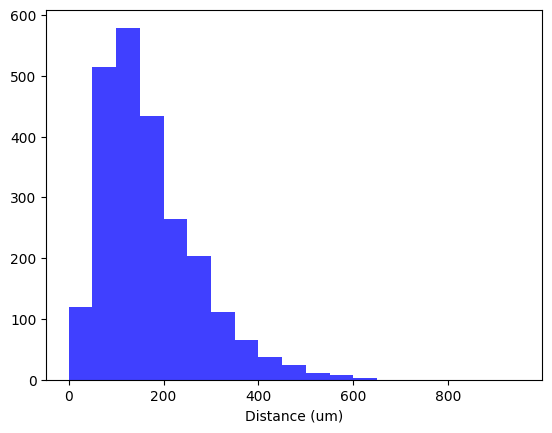

In [31]:
distance = index_pre_post[index_pre_post['population conn'] == 'L23E->L23E']['distance'].reset_index(drop=True)
plt.hist(distance, bins=range(0, 1000, 50), density=False, alpha=0.75, color='b', label='L23E->L23E')
plt.xlabel('Distance (um)')

In [32]:
import numpy as np3
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# --------------------------------------------------
# User controls
# --------------------------------------------------
bin_width = 50  # µm

pop_order = [
    # "L1I", "L1E",
    "L23I", "L23E",
    # "L4I", "L4E",
    # "L5I", "L5E",
    # "L6I", "L6E"
]

# --------------------------------------------------
# 1. Make sure the connection dataframe is binary
# --------------------------------------------------
# This avoids counting multiple synapses between the same pair
# as multiple connections.
index_pre_post_binary = (
    index_pre_post
    .drop_duplicates(subset=["pre", "post"])
    .copy()
)

# --------------------------------------------------
# 2. Use only population pairs with nonzero probability
# --------------------------------------------------
nonzero_pairs = conn_prob[conn_prob["prob"] > 0].copy()

# Optional, keep only populations that are in pop_order
nonzero_pairs = nonzero_pairs[
    nonzero_pairs["pre"].isin(pop_order) &
    nonzero_pairs["post"].isin(pop_order)
].copy()

# --------------------------------------------------
# 3. Global distance bins
# --------------------------------------------------
all_pos = ind_cell_df[["x_new", "y_new", "z_new"]].values.astype(float)

# A simple safe maximum distance
# You can also set this manually, for example dmax = 1000
dmax = np.linalg.norm(all_pos.max(axis=0) - all_pos.min(axis=0))

bins = np.arange(0, dmax + bin_width, bin_width)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

# --------------------------------------------------
# 4. Compute P(connection | distance) for all population pairs
# --------------------------------------------------
distance_prob_rows = []

for _, row in nonzero_pairs.iterrows():

    pop_pre = row["pre"]
    pop_post = row["post"]

    # Neurons from each population
    pre_cells = ind_cell_df[ind_cell_df["mtype"] == pop_pre]
    post_cells = ind_cell_df[ind_cell_df["mtype"] == pop_post]

    pre_indices = pre_cells.index.values
    post_indices = post_cells.index.values

    if len(pre_indices) == 0 or len(post_indices) == 0:
        continue

    pre_pos = pre_cells[["x_new", "y_new", "z_new"]].values.astype(float)
    post_pos = post_cells[["x_new", "y_new", "z_new"]].values.astype(float)

    # --------------------------------------------------
    # Possible distances
    # --------------------------------------------------
    D_possible = cdist(pre_pos, post_pos)

    # Remove autapses for same population
    if pop_pre == pop_post:
        mask = pre_indices[:, None] != post_indices[None, :]
        possible_distances = D_possible[mask]
    else:
        possible_distances = D_possible.ravel()

    possible_counts, _ = np.histogram(possible_distances, bins=bins)

    # --------------------------------------------------
    # Connected distances
    # --------------------------------------------------
    connected_block = index_pre_post_binary[
        (index_pre_post_binary["mtype pre"] == pop_pre) &
        (index_pre_post_binary["mtype post"] == pop_post)
    ].copy()

    connected_distances = connected_block["distance"].values.astype(float)

    connected_counts, _ = np.histogram(connected_distances, bins=bins)

    # --------------------------------------------------
    # Probability and densities
    # --------------------------------------------------
    prob_distance = np.full_like(bin_centers, np.nan, dtype=float)

    valid = possible_counts > 0
    prob_distance[valid] = connected_counts[valid] / possible_counts[valid]

    connected_density = np.full_like(bin_centers, np.nan, dtype=float)
    possible_density = np.full_like(bin_centers, np.nan, dtype=float)

    if connected_counts.sum() > 0:
        connected_density = connected_counts / connected_counts.sum()

    if possible_counts.sum() > 0:
        possible_density = possible_counts / possible_counts.sum()

    for k in range(len(bin_centers)):
        distance_prob_rows.append({
            "mtype pre": pop_pre,
            "mtype post": pop_post,
            "population conn": f"{pop_pre}->{pop_post}",
            "bin_start": bins[k],
            "bin_end": bins[k + 1],
            "bin_center": bin_centers[k],
            "connected_counts": connected_counts[k],
            "possible_counts": possible_counts[k],
            "prob_connection_given_distance": prob_distance[k],
            "connected_density": connected_density[k],
            "possible_density": possible_density[k],
            "original_pair_probability": row["prob"]
        })

distance_prob_df = pd.DataFrame(distance_prob_rows)

distance_prob_df.head(5)

,mtype pre,mtype post,population conn,bin_start,bin_end,bin_center,connected_counts,possible_counts,prob_connection_given_distance,connected_density,possible_density,original_pair_probability
0,L23E,L23E,L23E->L23E,0.0,50.0,25.0,119,7194,0.016542,0.050147,0.010531,0.001465
1,L23E,L23E,L23E->L23E,50.0,100.0,75.0,515,38222,0.013474,0.217025,0.055954,0.001465
2,L23E,L23E,L23E->L23E,100.0,150.0,125.0,579,68364,0.008469,0.243995,0.100079,0.001465
3,L23E,L23E,L23E->L23E,150.0,200.0,175.0,433,82454,0.005251,0.182469,0.120705,0.001465
4,L23E,L23E,L23E->L23E,200.0,250.0,225.0,264,84204,0.003135,0.111252,0.123267,0.001465


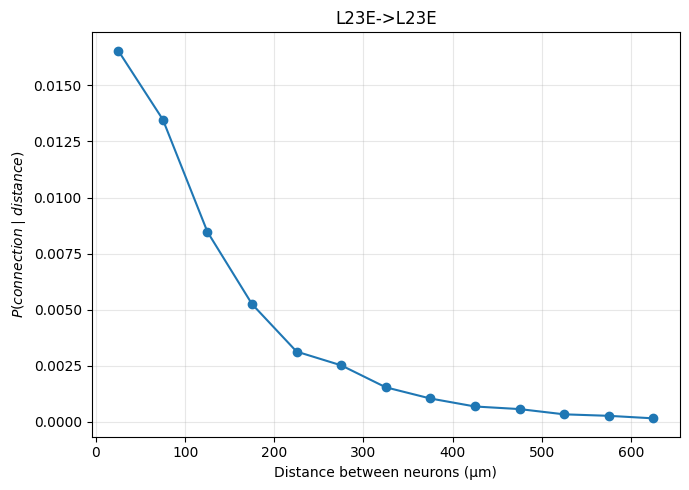

In [33]:
pop_conn = "L23E->L23E"
# pop_conn = "L23E->L4E"

df_plot = distance_prob_df[
    distance_prob_df["population conn"] == pop_conn
].copy()

df_plot = df_plot[
    (df_plot["possible_counts"] > 0) &
    (df_plot["prob_connection_given_distance"] > 0)
]

plt.figure(figsize=(7, 5))

plt.plot(
    df_plot["bin_center"],
    df_plot["prob_connection_given_distance"],
    "o-"
)

plt.xlabel("Distance between neurons (µm)")
plt.ylabel(r"$P(connection \mid distance)$")
plt.title(pop_conn)
#plt.yscale("log")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
from scipy.optimize import curve_fit

x_col = "bin_center"
y_col = "prob_connection_given_distance"

pop_conn = "L23I->L23E"
sub = distance_prob_df[distance_prob_df['population conn'] == pop_conn].copy()

x = sub[x_col].values.astype(float)
y =sub[y_col].values.astype(float)

# Keep only valid positive values
mask = np.isfinite(x) & np.isfinite(y) & (y > 0)

x = x[mask]
y = y[mask]

# Sort by x, useful for plotting
order = np.argsort(x)
x = x[order]
y = y[order]

# --------------------------------------------------
# Define models
# --------------------------------------------------
def exponential_model(d, A, lamb):
    return A * np.exp(-d / lamb)

def gaussian_model(d, A, sigma):
    return A * np.exp(-(d**2) / (2 * sigma**2))

# --------------------------------------------------
# Fit models
# --------------------------------------------------
popt_exp, pcov_exp = curve_fit(
    exponential_model,
    x,
    y,
    p0=[y.max(), 200],
    bounds=([0, 1e-9], [np.inf, np.inf]),
    maxfev=10000
)

popt_gauss, pcov_gauss = curve_fit(
    gaussian_model,
    x,
    y,
    p0=[y.max(), 200],
    bounds=([0, 1e-9], [np.inf, np.inf]),
    maxfev=10000
)

A_exp, lambda_exp = popt_exp
A_gauss, sigma_gauss = popt_gauss

# --------------------------------------------------
# Goodness of fit
# --------------------------------------------------
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

y_exp = exponential_model(x, *popt_exp)
y_gauss = gaussian_model(x, *popt_gauss)

r2_exp = r2_score(y, y_exp)
r2_gauss = r2_score(y, y_gauss)

rmse_exp = rmse(y, y_exp)
rmse_gauss = rmse(y, y_gauss)

# Log-space comparison, usually better for probabilities
log_y = np.log(y)
log_y_exp = np.log(y_exp)
log_y_gauss = np.log(y_gauss)

r2_log_exp = r2_score(log_y, log_y_exp)
r2_log_gauss = r2_score(log_y, log_y_gauss)

rmse_log_exp = rmse(log_y, log_y_exp)
rmse_log_gauss = rmse(log_y, log_y_gauss)

# --------------------------------------------------
# Print results
# --------------------------------------------------
print("Exponential fit:")
print(f"A      = {A_exp:.6e}")
print(f"lambda = {lambda_exp:.3f} µm")
print(f"R²     = {r2_exp:.4f}")
print(f"RMSE   = {rmse_exp:.6e}")
print(f"log R² = {r2_log_exp:.4f}")
print(f"log RMSE = {rmse_log_exp:.4f}")

print("\nGaussian fit:")
print(f"A      = {A_gauss:.6e}")
print(f"sigma  = {sigma_gauss:.3f} µm")
print(f"R²     = {r2_gauss:.4f}")
print(f"RMSE   = {rmse_gauss:.6e}")
print(f"log R² = {r2_log_gauss:.4f}")
print(f"log RMSE = {rmse_log_gauss:.4f}")


Exponential fit:
A      = 3.797435e-02
lambda = 87.920 µm
R²     = 0.9986
RMSE   = 3.164166e-04
log R² = 0.9350
log RMSE = 0.4723

Gaussian fit:
A      = 2.820980e-02
sigma  = 84.069 µm
R²     = 0.9788
RMSE   = 1.253842e-03
log R² = -10.6318
log RMSE = 6.3200


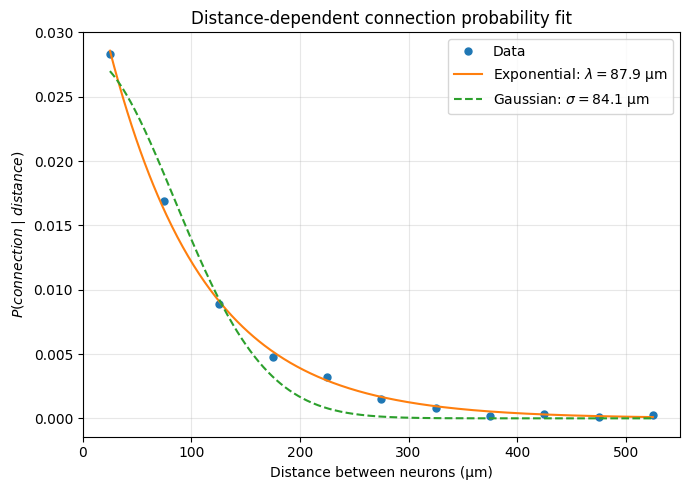

In [35]:
# --------------------------------------------------
# Plot data and fits
# --------------------------------------------------
d_plot = np.linspace(x.min(), x.max(), 500)

plt.figure(figsize=(7, 5))

plt.plot(
    x,
    y,
    "o",
    label="Data",
    markersize=5
)

plt.plot(
    d_plot,
    exponential_model(d_plot, *popt_exp),
    "-",
    label=fr"Exponential: $\lambda={lambda_exp:.1f}$ µm"
)

plt.plot(
    d_plot,
    gaussian_model(d_plot, *popt_gauss),
    "--",
    label=fr"Gaussian: $\sigma={sigma_gauss:.1f}$ µm"
)

plt.xlabel("Distance between neurons (µm)")
plt.ylabel(r"$P(connection \mid distance)$")
#plt.yscale("log")
plt.title("Distance-dependent connection probability fit")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
# type	connections
# EE	96193
# EI	18429
# IE	12973
# II	5463
